# Turtle data preprocessing

## Settings

### Imports

In [1]:
"""to clear all variables.
Always restart from here when modifying the code"""
%reset -f
dico_info={}

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import signal
import math
import os

In [3]:
import os

os.chdir(r"C:\Users\loren\Documents\Tortues\Martinique_Verte")

print(os.getcwd())

C:\Users\loren\Documents\Tortues\Martinique_Verte


##  Global parameters

In [4]:
%pwd

'C:\\Users\\loren\\Documents\\Tortues\\Martinique_Verte'

In [208]:

''
DIR_NAME='CC-07-115_14-05-2019'

""" Used to remove the measurements at the end that have no associated label.
Set to None to analyze the whole measurement series."""
CUT_INDEX=400000 # or None
""" Used to remove measurements at the beginning"""
CUT_INDEX_BEGIN=None
ANGLE_CORRECTION_INDEX = None

""" Used to shift the measurement series in time.
A value is computed automatically further below, but you should check that this
computation actually gives a sensible result."""

BEH_COL_NAME="Behavior"

""" Used to remove an atypical beginning or end.
Warning: this must be expressed in the final time zone (the one seen on the final plots)."""
KEPT_TIME_INTERVAL=(None,None)

delim=","
Pressure=None

#Behavior
#1/
if DIR_NAME=='CC-07-107_11-02-2019':
    SAMPLING_STEP=50
    CUT_INDEX=354802
    MES_TIME_DECAY=None
    KEPT_TIME_INTERVAL=("2019-02-11 11:54:37",None)
    Ax=-0.0894
    Ay=-0.0197
    Az=-0.9958
    DATE="11-02-2019"


#2/
elif DIR_NAME=='CC-07-108_11-02-2019':
    SAMPLING_STEP=50
    CUT_INDEX=160952
    MES_TIME_DECAY=None
    KEPT_TIME_INTERVAL=("2019-02-11 12:09:15",None)
    Ax=-0.0894
    Ay=-0.0197
    Az=-0.9958
    DATE="11-02-2019"


#3/
elif DIR_NAME=='CC-07-115_13-05-2019':
    SAMPLING_STEP=50 # millisecond
    CUT_INDEX=734326
    MES_TIME_DECAY=None
    KEPT_TIME_INTERVAL=('2019-05-13 08:31:29',None)
    Ax=-0.0113
    Ay=0.1021
    Az=-0.9948
    DATE="13-05-2019"


#4/
elif DIR_NAME=='CC-07-115_14-05-2019':
    SAMPLING_STEP=50 # millisecond
    CUT_INDEX=778609
    MES_TIME_DECAY=None
    KEPT_TIME_INTERVAL=('2019-05-14 06:18:00',None)
    Ax=-0.0113
    Ay=0.1021
    Az=-0.9948
    DATE="14-05-2019"


#5/
elif DIR_NAME=='CC-07-47_14-02-2018':
    SAMPLING_STEP=20 # millisecond
    CUT_INDEX=294855
    MES_TIME_DECAY=-1
    KEPT_TIME_INTERVAL=('2018-02-14 14:16:00',None)
    Ax=0.1440
    Ay=0.1064
    Az=-0.9838
    DATE="14-02-2018"


#6/
elif DIR_NAME=='CC-07-48_04-10-2018':
    SAMPLING_STEP=50
    CUT_INDEX=322321
    MES_TIME_DECAY=None
    KEPT_TIME_INTERVAL=('2018-10-04 09:46:07',None)
    Ax=-0.2588
    Ay=0.0054
    Az=-0.9659
    DATE="04-10-2018"



#7/
elif DIR_NAME=='CC-07-48_06-10-2018':
    SAMPLING_STEP=50
    CUT_INDEX=483303
    MES_TIME_DECAY=-1
    KEPT_TIME_INTERVAL=('2018-10-06 11:23:54',None)
    Ax=-0.4130
    Ay=0.0054
    Az=-0.9107
    DATE="06-10-2018"


#8/
elif DIR_NAME=='CC-07-48_08-04-2019_1':
    SAMPLING_STEP=50
    CUT_INDEX=165535
    MES_TIME_DECAY=None
    KEPT_TIME_INTERVAL=("2019-04-08 08:54:00",None)
    Ax=-0.24
    Ay=0.0677
    Az=-0.9684
    DATE="08-04-2019"
    delim=";"

#9/
elif DIR_NAME=='CC-07-48_08-04-2019_2':
    SAMPLING_STEP=50
    CUT_INDEX=None
    MES_TIME_DECAY=None
    KEPT_TIME_INTERVAL=("2019-04-08 12:31:00",None)
    Ax=-0.24
    Ay=0.0677
    Az=-0.9684
    DATE="08-04-2019"
    delim=";"

#10/
elif DIR_NAME=='CC-07-48_08-04-2019_3':
    SAMPLING_STEP=50
    CUT_INDEX=None
    MES_TIME_DECAY=None
    KEPT_TIME_INTERVAL=("2019-04-08 14:03:00",None)
    Ax=-0.24
    Ay=0.0677
    Az=-0.9684
    DATE="08-04-2019"
    delim=";"

#11/
elif DIR_NAME=='CC-07-48_08-10-2018':
    SAMPLING_STEP=50
    CUT_INDEX=574733
    MES_TIME_DECAY=-6
    KEPT_TIME_INTERVAL=("2018-10-08 10:34:00",None)
    Ax=-0.4993411
    Ay=-0.008053889
    Az=-0.6384538
    DATE="08-10-2018"

#12/
elif DIR_NAME=='CC-07-48_10-10-2018':
    SAMPLING_STEP=50
    CUT_INDEX=105599
    MES_TIME_DECAY=-6
    KEPT_TIME_INTERVAL=("2018-10-10 09:48:36",None)
    Ax=-0.3204
    Ay=0.0101
    Az=-9472
    DATE="10-10-2018"

#13/
elif DIR_NAME=='CC-07-48_18-02-2019':
    SAMPLING_STEP=50
    CUT_INDEX=584679
    MES_TIME_DECAY=None
    KEPT_TIME_INTERVAL=("2019-02-18 10:16:29",None)
    Ax=-0.2429
    Ay=-0.1129
    Az=-0.9634
    DATE="18-02-2019"
    Pressure=-1

#14/
elif DIR_NAME=='CC-07-48_22-05-2018':
    SAMPLING_STEP=20
    CUT_INDEX=715401
    MES_TIME_DECAY=None
    # no need for KEPT_TIME_INTERVAL here (we keep everything)
    Ax=-0-0.2157
    Ay=-0.0475
    Az=-0.9753
    DATE="22-05-2018"

#15 STILL VERY STRANGE./
elif DIR_NAME=='CC-07-48_26-05-2018':
    """ time jump at the beginning.
    A warning should appear
    """
    SAMPLING_STEP=20
    CUT_INDEX=903254
    #CUT_INDEX_BEGIN=10000 # #>129147 (the computed index of the large time jump)
                              #for the corrected file
    CUT_INDEX_BEGIN=130000 # for the raw file
    MES_TIME_DECAY=-6
    KEPT_TIME_INTERVAL=("2018-05-26 11:02:00","2018-05-26 14:44:45")
    Ax=-0.3525
    Ay=-0.0783
    Az=-0.9324
    DATE="26-05-2018"


#16/
elif DIR_NAME=='CC-07-59_20-05-2018':
    SAMPLING_STEP=20
    CUT_INDEX=1114236
    MES_TIME_DECAY=None
    KEPT_TIME_INTERVAL=("2018-05-20 08:45:23",None)
    Ax=-0.0553
    Ay=-0.0159
    Az=-0.9983
    DATE="20-05-2018"
    delim=";"


#17/
elif DIR_NAME=='CC-07-59_25-05-2018':
    SAMPLING_STEP=20
    CUT_INDEX=1125761
    MES_TIME_DECAY=None
    KEPT_TIME_INTERVAL=("2018-05-25 09:13:02",None)
    Ax=-0.1084
    Ay=-0.1196
    Az=-0.9868
    DATE="25-05-2018"


else:
    assert 1==0, "not implemented yet"




In [209]:
#DATE=DIR_NAME[10:21]
print("DATE:",DATE)

BEHAVIORS_FILE_PATH='Behavior/Behaviors_'+DIR_NAME+'.csv'
print("Behavior Path",BEHAVIORS_FILE_PATH)
#MESURES_NAME=DIR_NAME+'_treated_data.csv' # possibly work on the raw data

ACCELERO_FILE_PATH='Data-Accelero/'+DIR_NAME+'.csv'
print('Accelero Path', ACCELERO_FILE_PATH)

DATE: 14-05-2019
Behavior Path Behavior/Behaviors_CC-07-115_14-05-2019.csv
Accelero Path Data-Accelero/CC-07-115_14-05-2019.csv


In [210]:
OUT_DIR="out_A"

if not os.path.exists(OUT_DIR):
    os.makedirs(OUT_DIR)
else:
    print("output directory already exists")

output directory already exists


## Possible behaviours


In [211]:
# NOTE: these behavior names are the exact labels used by the annotation
# software and found in the "Behavior" column of the Behaviors_*.csv files.
# A few of them are in French (e.g. "Evitement", "Courant", "Nouvelle video")
# because that is how they were originally annotated. Do NOT translate them:
# the code below matches these strings exactly against the raw label files.
beh_str="""Acceleration
Basking
Breathing
Catching
Catching jellyfish
Chewing on movement
Chewing stationary
Chewing jellyfish
Escape
Evasion
Evitement
Feeding
Feeding stationary
Feeding on movement
Flipper beat
Foraging
Gliding ascent
Gliding descent
Grabbing on movement
Grabbing stationary
Grabbing the wall
Grabbing wall
Hunting jellyfish
Interaction
Landing
Nouvelle video
Obstacle
Prospection
Pursuit
Resting
Resting active
Resting in flow
Resting watching
Sand
Scratching
Scratching head
Scratching camera
Shaking
Shaking head
Head shaking
Stay in surface
Stepping back
Swimming 1 ascent
Swimming 1 descent
Swimming 1 horizontally
Swimming ascent
Swimming descent
Swimming horizontally
Swimming fastly ascent
Swimming fastly descent
Swimming fastly horizontally
Swimming on place
Swimming on the bottom
Time mark
Left U-turn
Right U-turn
Watching
Walking on sand
Courant
Regurgitating"""

In [212]:
behName_to_behInd={}
behInd_to_behName={}

for i,name in enumerate(beh_str.split("\n")):
    print(i,name)
    behName_to_behInd[name]=i
    behInd_to_behName[i]=name

behName_to_behInd["no behavior"]=-1
behInd_to_behName[-1]="no behavior"


import json
with open(OUT_DIR+"/behName_to_behInd.json", 'w') as f:
    json.dump(json.dumps(behName_to_behInd), f)

with open(OUT_DIR+"/behInd_to_behName.json", 'w') as f:
    json.dump(json.dumps(behInd_to_behName), f)



del beh_str

0 Acceleration
1 Basking
2 Breathing
3 Catching
4 Catching jellyfish
5 Chewing on movement
6 Chewing stationary
7 Chewing jellyfish
8 Escape
9 Evasion
10 Evitement
11 Feeding
12 Feeding stationary
13 Feeding on movement
14 Flipper beat
15 Foraging
16 Gliding ascent
17 Gliding descent
18 Grabbing on movement
19 Grabbing stationary
20 Grabbing the wall
21 Grabbing wall
22 Hunting jellyfish
23 Interaction
24 Landing
25 Nouvelle video
26 Obstacle
27 Prospection
28 Pursuit
29 Resting
30 Resting active
31 Resting in flow
32 Resting watching
33 Sand
34 Scratching
35 Scratching head
36 Scratching camera
37 Shaking
38 Shaking head
39 Head shaking
40 Stay in surface
41 Stepping back
42 Swimming 1 ascent
43 Swimming 1 descent
44 Swimming 1 horizontally
45 Swimming ascent
46 Swimming descent
47 Swimming horizontally
48 Swimming fastly ascent
49 Swimming fastly descent
50 Swimming fastly horizontally
51 Swimming on place
52 Swimming on the bottom
53 Time mark
54 Left U-turn
55 Right U-turn
56 Watch

## Processing the behavior file

### Transform into a dataframe

In [213]:
df=pd.read_csv(BEHAVIORS_FILE_PATH,delimiter=";")
len(df)

224

In [214]:
df.head()

,HeureDeb,DeciDeb,HeureFin,DeciFin,Behavior,Debut (s),Fin (s),Start (s),Stop (s),Duration (s),heure,Unnamed: 11
0,06:18:22,0.9,06:19:23,0.1,Stay in surface,22702.9,22763.1,22702.9,22763.1,60.2,00:00:00,0.0
1,06:19:23,0.1,06:19:33,0.2,Swimming descent,22763.1,22773.2,22763.1,22773.2,10.1,NaN,NaN
2,06:19:33,0.2,06:20:02,0.3,Gliding descent,22773.2,22802.3,22773.2,22802.3,29.1,NaN,NaN
3,06:20:02,0.3,06:20:15,0.2,Swimming horizontally,22802.3,22815.2,22802.3,22815.2,12.9,NaN,NaN
4,06:20:15,0.2,06:21:01,0.2,Swimming ascent,22815.2,22861.2,22815.2,22861.2,46.0,NaN,NaN


In [215]:
df.tail()

,HeureDeb,DeciDeb,HeureFin,DeciFin,Behavior,Debut (s),Fin (s),Start (s),Stop (s),Duration (s),heure,Unnamed: 11
219,10:31:15,0.5,10:46:50,0.8,Resting watching,37875.5,38810.8,37875.5,38810.8,935.3,NaN,NaN
220,10:46:50,0.8,10:46:57,0.4,Scratching,38810.8,38817.4,38810.8,38817.4,6.6,NaN,NaN
221,10:46:57,0.4,10:47:07,0.3,Swimming ascent,38817.4,38827.3,38817.4,38827.3,9.9,NaN,NaN
222,10:47:07,0.3,10:47:17,0.9,Gliding ascent,38827.3,38837.9,38827.3,38837.9,10.6,NaN,NaN
223,10:47:17,0.9,10:48:50,0.4,Stay in surface,38837.9,38930.4,38837.9,38930.4,92.5,NaN,NaN


### Transform strings into date+time

In [216]:
NONE_date=pd.to_datetime("1900-01-01")

In [217]:
"""Warning: potential bug if the interval crosses midnight,
since the date is read from the file name (global variable DATE)."""
def concat_hour_decisecond(hour,deci):
    deci_str=str(deci)

    if hour[-2]=='60':
        res_str= DATE + ' ' + hour
    else:
        res_str= DATE + ' ' + hour+deci_str[1:5]
    try:
        res=pd.to_datetime(res_str, format='%d-%m-%Y %H:%M:%S.%f')
    except Exception as e:
        print("PROBLEM:")
        print(e)
        print(res_str)
        print(deci)
        res=NONE_date

    return res


# Note the capital 'F' in 'DeciFin', which is not present in 'DeciDeb'
# (these are the exact column names as they appear in the source Behavior CSV files)
def concat_start(line):
    return concat_hour_decisecond(line['HeureDeb'],line['DeciDeb'])


def concat_end(line):
    return concat_hour_decisecond(line['HeureFin'],line['DeciFin'])


In [218]:
df['datetime_deb']=df.apply(concat_start,axis=1)
df['datetime_fin']=df.apply(concat_end,axis=1)

df.head()

,HeureDeb,DeciDeb,HeureFin,DeciFin,Behavior,Debut (s),Fin (s),Start (s),Stop (s),Duration (s),heure,Unnamed: 11,datetime_deb,datetime_fin
0,06:18:22,0.9,06:19:23,0.1,Stay in surface,22702.9,22763.1,22702.9,22763.1,60.2,00:00:00,0.0,2019-05-14 06:18:22.900,2019-05-14 06:19:23.100
1,06:19:23,0.1,06:19:33,0.2,Swimming descent,22763.1,22773.2,22763.1,22773.2,10.1,NaN,NaN,2019-05-14 06:19:23.100,2019-05-14 06:19:33.200
2,06:19:33,0.2,06:20:02,0.3,Gliding descent,22773.2,22802.3,22773.2,22802.3,29.1,NaN,NaN,2019-05-14 06:19:33.200,2019-05-14 06:20:02.300
3,06:20:02,0.3,06:20:15,0.2,Swimming horizontally,22802.3,22815.2,22802.3,22815.2,12.9,NaN,NaN,2019-05-14 06:20:02.300,2019-05-14 06:20:15.200
4,06:20:15,0.2,06:21:01,0.2,Swimming ascent,22815.2,22861.2,22815.2,22861.2,46.0,NaN,NaN,2019-05-14 06:20:15.200,2019-05-14 06:21:01.200


In [219]:
problems=(df['datetime_deb']==NONE_date)|(df['datetime_fin']==NONE_date)
nb_prob=sum(problems)
if nb_prob>0:
    print("warning: %d rows were removed due to a date problem"%nb_prob)
    df=df[~problems].copy()

### Cleanup

In [220]:
"we only keep what is necessary"
beh_df=df[["datetime_deb","datetime_fin",BEH_COL_NAME]].copy()
beh_df.head()

,datetime_deb,datetime_fin,Behavior
0,2019-05-14 06:18:22.900,2019-05-14 06:19:23.100,Stay in surface
1,2019-05-14 06:19:23.100,2019-05-14 06:19:33.200,Swimming descent
2,2019-05-14 06:19:33.200,2019-05-14 06:20:02.300,Gliding descent
3,2019-05-14 06:20:02.300,2019-05-14 06:20:15.200,Swimming horizontally
4,2019-05-14 06:20:15.200,2019-05-14 06:21:01.200,Swimming ascent


In [221]:
beh_df.tail()

,datetime_deb,datetime_fin,Behavior
219,2019-05-14 10:31:15.500,2019-05-14 10:46:50.800,Resting watching
220,2019-05-14 10:46:50.800,2019-05-14 10:46:57.400,Scratching
221,2019-05-14 10:46:57.400,2019-05-14 10:47:07.300,Swimming ascent
222,2019-05-14 10:47:07.300,2019-05-14 10:47:17.900,Gliding ascent
223,2019-05-14 10:47:17.900,2019-05-14 10:48:50.400,Stay in surface


In [222]:
"""we convert the behavior strings into (integer) indices"""
beh_df[BEH_COL_NAME].replace(behName_to_behInd,inplace=True)

C:\Users\loren\AppData\Local\Temp\ipykernel_18120\3326910788.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  beh_df[BEH_COL_NAME].replace(behName_to_behInd,inplace=True)
C:\Users\loren\AppData\Local\Temp\ipykernel_18120\3326910788.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  beh_df[BEH_CO

In [223]:
beh_df.dtypes

datetime_deb    datetime64[ns]
datetime_fin    datetime64[ns]
Behavior                 int64
dtype: object

### Computing the interesting time interval

This step is used to compute an index for cutting the measurement series

In [224]:
MIN_LABEL_TIME=min(beh_df['datetime_deb'])
MAX_LABEL_TIME=max(beh_df['datetime_fin'])
MIN_LABEL_TIME,MAX_LABEL_TIME

(Timestamp('2019-05-14 06:18:22.900000'),
 Timestamp('2019-05-14 10:48:50.400000'))

## Processing the measurement file

### Import and initial trimming

In [225]:
print("file:",ACCELERO_FILE_PATH)

mesures_df= pd.read_csv(ACCELERO_FILE_PATH,delimiter=delim,encoding = "ISO-8859-1")

len(mesures_df)

file: Data-Accelero/CC-07-115_14-05-2019.csv


1728000

In [226]:
mesures_df.head()

,Date (local),Time (local),Accelerometer X [m/s²],Accelerometer Y [m/s²],Accelerometer Z [m/s²],Gyroscope X [mrad/s],Gyroscope Y [mrad/s],Gyroscope Z [mrad/s],Magnetometer X [µT],Magnetometer Y [µT],Magnetometer Z [µT],Temperature (imu) [°C],Depth (100bar) 1 [m],Depth (100bar) 2 [°C],Light intensity 1 [raw],Light intensity 2 [raw]
0,14.05.2019,00:00:00.000000,-0.160412,1.139640,-10.496180,-88.862800,15.963377,-42.036894,76.874414,-42.049219,-59.288086,30.43,4.512294,27.15,0,0
1,14.05.2019,00:00:00.050000,-0.088585,1.144428,-10.455479,-90.991251,12.770702,-42.036894,75.276562,-41.507812,-59.115234,30.43,4.512294,27.15,0,0
2,14.05.2019,00:00:00.100000,-0.112527,1.142034,-10.496180,-90.459138,15.431265,-40.972668,76.164258,-41.327344,-57.559570,30.43,4.512294,27.15,0,0
3,14.05.2019,00:00:00.150000,-0.124498,1.113304,-10.467450,-92.055476,12.238589,-40.440556,75.454102,-41.688281,-58.596680,30.43,4.512294,27.15,0,0
4,14.05.2019,00:00:00.200000,-0.119710,1.185130,-10.448296,-92.587588,12.238589,-39.908443,76.696875,-41.146875,-58.423828,30.43,4.512294,27.15,0,0


In [227]:
mesures_df.tail()

,Date (local),Time (local),Accelerometer X [m/s²],Accelerometer Y [m/s²],Accelerometer Z [m/s²],Gyroscope X [mrad/s],Gyroscope Y [mrad/s],Gyroscope Z [mrad/s],Magnetometer X [µT],Magnetometer Y [µT],Magnetometer Z [µT],Temperature (imu) [°C],Depth (100bar) 1 [m],Depth (100bar) 2 [°C],Light intensity 1 [raw],Light intensity 2 [raw]
1727995,14.05.2019,23:59:59.750000,-2.367865,-1.702277,8.611943,161.230111,377.267817,-162.294336,57.877734,-79.406250,-106.822266,30.36,0.622385,27.09,0,0
1727996,14.05.2019,23:59:59.800000,-2.305616,-1.795651,8.877700,206.459680,353.854864,83.541675,59.120508,-79.225781,-105.266602,30.37,0.622385,27.11,0,0
1727997,14.05.2019,23:59:59.850000,-2.796428,-1.419762,8.650251,56.936046,128.771244,8.513801,59.830664,-78.503906,-105.958008,30.37,0.622385,27.11,0,0
1727998,14.05.2019,23:59:59.900000,-2.839523,-1.599327,8.520964,-187.835740,25.009291,-75.027873,59.830664,-79.586719,-106.649414,30.37,0.622385,27.11,0,0
1727999,14.05.2019,23:59:59.950000,-2.782062,-1.975216,8.453926,-68.110410,20.752390,-68.642522,61.250977,-78.142969,-105.612305,30.37,0.622385,27.11,0,0


In [187]:
mesures_df.columns

Index(['Date (local)', 'Time (local)', 'Accelerometer X [m/s²]',
       'Accelerometer Y [m/s²]', 'Accelerometer Z [m/s²]',
       'Gyroscope X [mrad/s]', 'Gyroscope Y [mrad/s]', 'Gyroscope Z [mrad/s]',
       'Magnetometer X [µT]', 'Magnetometer Y [µT]', 'Magnetometer Z [µT]',
       'Temperature (imu) [°C]', 'Depth (30bar) 1 [m]', 'Depth (30bar) 2 [°C]',
       'Light intensity 1 [raw]', 'Light intensity 2 [raw]'],
      dtype='object')

In [95]:
time_data_change_name_dict = {' Time (local)':'Time (local)', " Date (local)":"Date (local)"}
try:
    mesures_df.rename(columns=time_data_change_name_dict, inplace=True)
    print("Done")
except Exception:
    print("Names were not changed. Probably it is already fine.")

Done


In [96]:

try:
    mesures_df=mesures_df[["Date (local)","Time (local)","Accelerometer X [m/s²]","Accelerometer Y [m/s²]","Accelerometer Z [m/s²]","Gyroscope X [mrad/s]","Gyroscope Y [mrad/s]","Gyroscope Z [mrad/s]","Magnetometer X [µT]","Magnetometer Y [µT]","Magnetometer Z [µT]","Depth (100bar) 1 [m]","Light intensity 1 [raw]","Temperature (imu) [°C]"]].copy()
    mesures_df.rename(columns={"Depth (100bar) 1 [m]":"Depth [m]"}, inplace=True)
    print("Done 1.")
except Exception:
    print("Depth != 100")

try:
    mesures_df=mesures_df[["Date (local)","Time (local)","Accelerometer X [m/s²]","Accelerometer Y [m/s²]","Accelerometer Z [m/s²]","Gyroscope X [mrad/s]","Gyroscope Y [mrad/s]","Gyroscope Z [mrad/s]","Magnetometer X [µT]","Magnetometer Y [µT]","Magnetometer Z [µT]","Depth (30bar) 1 [m]","Light intensity 1 [raw]","Temperature (imu) [°C]"]].copy()
    mesures_df.rename(columns={"Depth (30bar) 1 [m]":"Depth [m]"}, inplace=True)
    print("Done 2.")
except Exception:
    print("Depth != 30")

Depth != 100
Done 2.


In [97]:
mesures_df.head()

,Date (local),Time (local),Accelerometer X [m/s²],Accelerometer Y [m/s²],Accelerometer Z [m/s²],Gyroscope X [mrad/s],Gyroscope Y [mrad/s],Gyroscope Z [mrad/s],Magnetometer X [µT],Magnetometer Y [µT],Magnetometer Z [µT],Depth [m],Light intensity 1 [raw],Temperature (imu) [°C]
0,11.02.2019,12:08:42.000000,0.483629,-0.062249,-10.424354,-47.358019,-23.945066,-22.348728,25.754883,4.321289,-105.706055,0.59749,8335,32.37
1,11.02.2019,12:08:42.050000,0.497994,-0.088585,-10.369287,-48.954357,-29.798304,-21.816616,26.100586,4.666992,-106.374023,0.59749,8335,32.37
2,11.02.2019,12:08:42.100000,0.524330,-0.052672,-10.405200,-48.954357,-24.477179,-22.880841,24.026367,5.704102,-107.041992,0.59749,8335,32.37
3,11.02.2019,12:08:42.150000,0.526724,-0.069432,-10.414777,-44.697456,-26.605629,-17.559715,26.791992,6.049805,-107.041992,0.59749,8335,32.37
4,11.02.2019,12:08:42.200000,0.521936,-0.057461,-10.438719,-45.761682,-25.009291,-18.623940,25.754883,3.975586,-105.372070,0.59749,8335,32.37


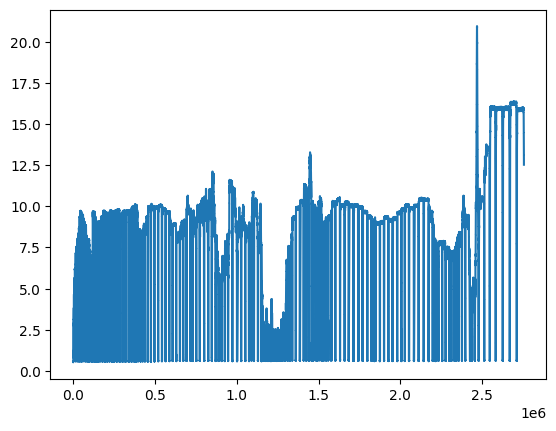

In [98]:
plt.plot(mesures_df['Depth [m]'])

(array([ 337396.,  100340.,  125320.,  468410., 1422645.,   72236.,
          40480.,  184580.,    1480.,    2340.]),
 array([ 0.52280372,  2.56453897,  4.60627423,  6.64800948,  8.68974473,
        10.73147998, 12.77321523, 14.81495049, 16.85668574, 18.89842099,
        20.94015624]),
 <BarContainer object of 10 artists>)

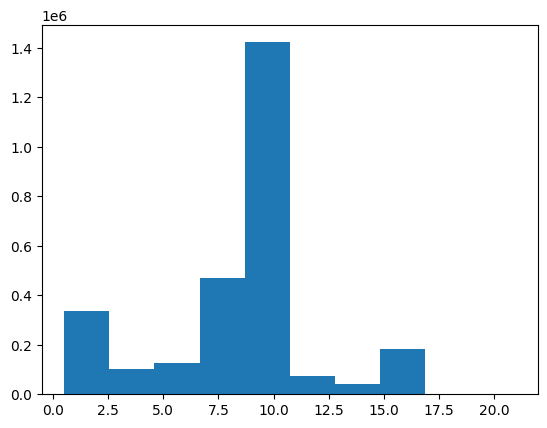

In [99]:
plt.hist(mesures_df['Depth [m]'])

In [100]:
print("the manually entered CUT_INDEX is:",CUT_INDEX)

if CUT_INDEX is None:
    CUT_INDEX=-1
else:
    print("measurements will be cut at the end at index:",CUT_INDEX)

if CUT_INDEX_BEGIN is None:
    CUT_INDEX_BEGIN=0
else:
    print("measurements will be cut at the beginning at index:",CUT_INDEX_BEGIN)

""".copy() to avoid a lot of warnings later on"""
mesure=mesures_df[CUT_INDEX_BEGIN:CUT_INDEX].copy()
nb_suppr=len(mesures_df)-len(mesure)
print("number of measurements removed:",nb_suppr)


the manually entered CUT_INDEX is: 160952
measurements will be cut at the end at index: 160952
number of measurements removed: 2594275


### Time indexing $\sharp$

Below: the only long step (between 30s and 10 minutes). This is why it's better to cut the measurement series by removing the end where there is no label.


In [101]:
%%time
 mesure['datetime']=pd.to_datetime(mesure['Date (local)'] + ' ' + mesure['Time (local)'],format='%d.%m.%Y %H:%M:%S.%f')

CPU times: total: 375 ms
Wall time: 385 ms


In [102]:
mesure.drop(['Date (local)','Time (local)'], axis=1, inplace=True)

In [103]:
mesure.head()

,Accelerometer X [m/s²],Accelerometer Y [m/s²],Accelerometer Z [m/s²],Gyroscope X [mrad/s],Gyroscope Y [mrad/s],Gyroscope Z [mrad/s],Magnetometer X [µT],Magnetometer Y [µT],Magnetometer Z [µT],Depth [m],Light intensity 1 [raw],Temperature (imu) [°C],datetime
0,0.483629,-0.062249,-10.424354,-47.358019,-23.945066,-22.348728,25.754883,4.321289,-105.706055,0.59749,8335,32.37,2019-02-11 12:08:42.000
1,0.497994,-0.088585,-10.369287,-48.954357,-29.798304,-21.816616,26.100586,4.666992,-106.374023,0.59749,8335,32.37,2019-02-11 12:08:42.050
2,0.524330,-0.052672,-10.405200,-48.954357,-24.477179,-22.880841,24.026367,5.704102,-107.041992,0.59749,8335,32.37,2019-02-11 12:08:42.100
3,0.526724,-0.069432,-10.414777,-44.697456,-26.605629,-17.559715,26.791992,6.049805,-107.041992,0.59749,8335,32.37,2019-02-11 12:08:42.150
4,0.521936,-0.057461,-10.438719,-45.761682,-25.009291,-18.623940,25.754883,3.975586,-105.372070,0.59749,8335,32.37,2019-02-11 12:08:42.200


### Accelerometer data correction

In [104]:
if Pressure is not None:
    mesure.iloc[:,9]=mesure.iloc[:,9]*Pressure



In [105]:
FREQ=(1/SAMPLING_STEP)*1000
print(FREQ)

20.0


In [106]:


AccX=mesure.iloc[:,0]
AccY=mesure.iloc[:,1]
AccZ=mesure.iloc[:,1]


mask_length=int(1*FREQ)
#print(mask_length)
mask = np.ones(mask_length)/mask_length

StX = np.convolve(AccX,mask,mode='same')
StY = np.convolve(AccY,mask,mode='same')
StZ = np.convolve(AccZ,mask,mode='same')

DX=AccX-StX
DY=AccY-StY
DZ=AccZ-StZ
dba = np.sqrt(DX**2 + DY**2 + DZ**2)



GyrX=mesure.iloc[:,3].copy()
GyrY=mesure.iloc[:,4].copy()
GyrZ=mesure.iloc[:,5].copy()

ra = np.sqrt(GyrX**2 + GyrY**2 + GyrZ**2)



mesure['StX']=StX
mesure['StY']=StY
mesure['StZ']=StZ
mesure['DX']=DX
mesure['DY']=DY
mesure['DZ']=DZ
mesure['DBA']=dba
mesure['RA']=ra
mesure.head()

,Accelerometer X [m/s²],Accelerometer Y [m/s²],Accelerometer Z [m/s²],Gyroscope X [mrad/s],Gyroscope Y [mrad/s],Gyroscope Z [mrad/s],Magnetometer X [µT],Magnetometer Y [µT],Magnetometer Z [µT],Depth [m],...,Temperature (imu) [°C],datetime,StX,StY,StZ,DX,DY,DZ,DBA,RA
0,0.483629,-0.062249,-10.424354,-47.358019,-23.945066,-22.348728,25.754883,4.321289,-105.706055,0.59749,...,32.37,2019-02-11 12:08:42.000,0.256299,-0.034955,-0.034955,0.227329,-0.027294,-0.027294,0.230583,57.581367
1,0.497994,-0.088585,-10.369287,-48.954357,-29.798304,-21.816616,26.100586,4.666992,-106.374023,0.59749,...,32.37,2019-02-11 12:08:42.050,0.282157,-0.038786,-0.038786,0.215837,-0.049799,-0.049799,0.227037,61.322367
2,0.524330,-0.052672,-10.405200,-48.954357,-24.477179,-22.880841,24.026367,5.704102,-107.041992,0.59749,...,32.37,2019-02-11 12:08:42.100,0.306099,-0.043455,-0.043455,0.218231,-0.009218,-0.009218,0.218620,59.322797
3,0.526724,-0.069432,-10.414777,-44.697456,-26.605629,-17.559715,26.791992,6.049805,-107.041992,0.59749,...,32.37,2019-02-11 12:08:42.150,0.331358,-0.046807,-0.046807,0.195367,-0.022625,-0.022625,0.197970,54.900507
4,0.521936,-0.057461,-10.438719,-45.761682,-25.009291,-18.623940,25.754883,3.975586,-105.372070,0.59749,...,32.37,2019-02-11 12:08:42.200,0.357933,-0.049440,-0.049440,0.164003,-0.008021,-0.008021,0.164395,55.375512


### Computing and optionally applying `MES_TIME_DECAY`

In [107]:
mesure.head()

,Accelerometer X [m/s²],Accelerometer Y [m/s²],Accelerometer Z [m/s²],Gyroscope X [mrad/s],Gyroscope Y [mrad/s],Gyroscope Z [mrad/s],Magnetometer X [µT],Magnetometer Y [µT],Magnetometer Z [µT],Depth [m],...,Temperature (imu) [°C],datetime,StX,StY,StZ,DX,DY,DZ,DBA,RA
0,0.483629,-0.062249,-10.424354,-47.358019,-23.945066,-22.348728,25.754883,4.321289,-105.706055,0.59749,...,32.37,2019-02-11 12:08:42.000,0.256299,-0.034955,-0.034955,0.227329,-0.027294,-0.027294,0.230583,57.581367
1,0.497994,-0.088585,-10.369287,-48.954357,-29.798304,-21.816616,26.100586,4.666992,-106.374023,0.59749,...,32.37,2019-02-11 12:08:42.050,0.282157,-0.038786,-0.038786,0.215837,-0.049799,-0.049799,0.227037,61.322367
2,0.524330,-0.052672,-10.405200,-48.954357,-24.477179,-22.880841,24.026367,5.704102,-107.041992,0.59749,...,32.37,2019-02-11 12:08:42.100,0.306099,-0.043455,-0.043455,0.218231,-0.009218,-0.009218,0.218620,59.322797
3,0.526724,-0.069432,-10.414777,-44.697456,-26.605629,-17.559715,26.791992,6.049805,-107.041992,0.59749,...,32.37,2019-02-11 12:08:42.150,0.331358,-0.046807,-0.046807,0.195367,-0.022625,-0.022625,0.197970,54.900507
4,0.521936,-0.057461,-10.438719,-45.761682,-25.009291,-18.623940,25.754883,3.975586,-105.372070,0.59749,...,32.37,2019-02-11 12:08:42.200,0.357933,-0.049440,-0.049440,0.164003,-0.008021,-0.008021,0.164395,55.375512


Normally, the measurement interval should cover roughly all the labels. This is not always the case.

In [108]:
MIN_LABEL_TIME,MAX_LABEL_TIME

(Timestamp('2019-02-11 12:10:15'), Timestamp('2019-02-11 14:22:49.500000'))

In [109]:
mini_time_mes=mesure["datetime"][CUT_INDEX_BEGIN]
maxi_time_mes=mesure["datetime"][len(mesure)-1]
mini_time_mes,maxi_time_mes

(Timestamp('2019-02-11 12:08:42'), Timestamp('2019-02-11 14:22:49.550000'))

In [110]:
"""indicative calculation of a time offset.
This value must then be reported into the global variable MES_TIME_DECAY"""
import datetime

diff_h=MIN_LABEL_TIME.hour-mini_time_mes.hour
diff_m=MIN_LABEL_TIME.minute-mini_time_mes.minute
diff_s=MIN_LABEL_TIME.second-mini_time_mes.second
diff_mms=MIN_LABEL_TIME.microsecond-mini_time_mes.microsecond


print("suggested hour difference:",diff_h)
print("minute difference:",diff_m)
print("second difference:",diff_s)
print("microsecond difference:",diff_mms)

suggested hour difference: 0
minute difference: 2
second difference: -27
microsecond difference: 0


In [111]:
if MES_TIME_DECAY is not None:
    delta=pd.Timedelta(MES_TIME_DECAY, unit='h')
    print("time offset applied:",delta)
    mes=mesure.copy()
    mes.datetime=mes.datetime+delta

    del mesure

else:
    mes=mesure



In [112]:
mes.head()

,Accelerometer X [m/s²],Accelerometer Y [m/s²],Accelerometer Z [m/s²],Gyroscope X [mrad/s],Gyroscope Y [mrad/s],Gyroscope Z [mrad/s],Magnetometer X [µT],Magnetometer Y [µT],Magnetometer Z [µT],Depth [m],...,Temperature (imu) [°C],datetime,StX,StY,StZ,DX,DY,DZ,DBA,RA
0,0.483629,-0.062249,-10.424354,-47.358019,-23.945066,-22.348728,25.754883,4.321289,-105.706055,0.59749,...,32.37,2019-02-11 12:08:42.000,0.256299,-0.034955,-0.034955,0.227329,-0.027294,-0.027294,0.230583,57.581367
1,0.497994,-0.088585,-10.369287,-48.954357,-29.798304,-21.816616,26.100586,4.666992,-106.374023,0.59749,...,32.37,2019-02-11 12:08:42.050,0.282157,-0.038786,-0.038786,0.215837,-0.049799,-0.049799,0.227037,61.322367
2,0.524330,-0.052672,-10.405200,-48.954357,-24.477179,-22.880841,24.026367,5.704102,-107.041992,0.59749,...,32.37,2019-02-11 12:08:42.100,0.306099,-0.043455,-0.043455,0.218231,-0.009218,-0.009218,0.218620,59.322797
3,0.526724,-0.069432,-10.414777,-44.697456,-26.605629,-17.559715,26.791992,6.049805,-107.041992,0.59749,...,32.37,2019-02-11 12:08:42.150,0.331358,-0.046807,-0.046807,0.195367,-0.022625,-0.022625,0.197970,54.900507
4,0.521936,-0.057461,-10.438719,-45.761682,-25.009291,-18.623940,25.754883,3.975586,-105.372070,0.59749,...,32.37,2019-02-11 12:08:42.200,0.357933,-0.049440,-0.049440,0.164003,-0.008021,-0.008021,0.164395,55.375512


In [113]:
mes.tail()

,Accelerometer X [m/s²],Accelerometer Y [m/s²],Accelerometer Z [m/s²],Gyroscope X [mrad/s],Gyroscope Y [mrad/s],Gyroscope Z [mrad/s],Magnetometer X [µT],Magnetometer Y [µT],Magnetometer Z [µT],Depth [m],...,Temperature (imu) [°C],datetime,StX,StY,StZ,DX,DY,DZ,DBA,RA
160947,-3.572149,-0.627281,-9.706094,-31.394642,26.073516,-6.917463,64.992188,9.679688,-114.222656,7.814048,...,34.11,2019-02-11 14:22:49.350,-2.702814,-0.496198,-0.496198,-0.869335,-0.131083,-0.131083,0.888880,41.392066
160948,-3.517082,-0.651223,-9.658209,-23.412953,26.605629,-10.642252,64.646484,12.099609,-113.554688,7.814048,...,34.11,2019-02-11 14:22:49.400,-2.517623,-0.455976,-0.455976,-0.999459,-0.195247,-0.195247,1.036900,37.003829
160949,-3.531447,-0.612916,-9.569624,-20.752390,25.541404,-11.706477,65.510742,12.618164,-113.721680,7.814048,...,34.11,2019-02-11 14:22:49.450,-2.331713,-0.418506,-0.418506,-1.199734,-0.194409,-0.194409,1.230834,34.929452
160950,-3.500323,-0.617704,-9.706094,-20.752390,18.091828,-14.899152,64.300781,10.716797,-113.554688,7.814048,...,34.11,2019-02-11 14:22:49.500,-2.147000,-0.381875,-0.381875,-1.353322,-0.235829,-0.235829,1.393812,31.304324
160951,-3.462016,-0.588974,-9.643844,-17.027602,18.091828,-15.963377,64.127930,11.235352,-113.721680,7.814048,...,34.11,2019-02-11 14:22:49.550,-1.963485,-0.346202,-0.346202,-1.498531,-0.242772,-0.242772,1.537358,29.531050


### Computing `CUT_INDEX` to speed up a future indexing

Warning: this calculation is only valid if the behavior file is properly time-aligned.

In [46]:
""" used to compute the cut index if this has never been done before"""
compute_CUT_INDEX=True
if compute_CUT_INDEX:
    datetime=mes['datetime']
    interesting=datetime[datetime<MAX_LABEL_TIME]
    """TODO: set CUT_INDEX to the value below to speed up next time"""
    print("the suggested CUT_INDEX is:",(len(interesting)+1))
    print("report this value in the global parameters to speed up indexing next time")


the suggested CUT_INDEX is: 354801
report this value in the global parameters to speed up indexing next time


### Time becomes the main index

In [47]:
""" time becomes the dataframe index"""
mes.set_index('datetime', inplace=True)

In [48]:
MIN_LABEL_TIME,MAX_LABEL_TIME

(Timestamp('2019-02-11 11:55:37.300000'), Timestamp('2019-02-11 16:43:04'))

In [49]:
mini_time_mes=mes.index[0]
maxi_time_mes=mes.index[len(mes)-1]
mini_time_mes,maxi_time_mes

(Timestamp('2019-02-11 11:47:24'), Timestamp('2019-02-11 16:43:04.050000'))

In [50]:
mes.head(5)

,Accelerometer X [m/s²],Accelerometer Y [m/s²],Accelerometer Z [m/s²],Gyroscope X [mrad/s],Gyroscope Y [mrad/s],Gyroscope Z [mrad/s],Magnetometer X [µT],Magnetometer Y [µT],Magnetometer Z [µT],Depth [m],Light intensity 1 [raw],Temperature (imu) [°C],StX,StY,StZ,DX,DY,DZ,DBA,RA
datetime,,,,,,,,,,,,,,,,,,,,
2019-02-11 11:47:24.000,-0.921768,-0.203507,-10.271125,-32.990980,1.596338,6.917463,44.472656,8.261719,3.908203,0.429446,7172,33.03,-0.466630,-0.100317,-0.100317,-0.455138,-0.103190,-0.103190,0.477961,33.746175
2019-02-11 11:47:24.050,-0.964863,-0.205901,-10.254366,-32.990980,-0.532113,6.917463,45.703125,8.085938,3.058594,0.429446,7172,33.03,-0.514155,-0.109295,-0.109295,-0.450708,-0.096606,-0.096606,0.470960,33.712597
2019-02-11 11:47:24.100,-0.945710,-0.210690,-10.268731,-33.523092,-1.064225,7.981689,44.296875,6.679688,3.738281,0.429446,7172,33.03,-0.560363,-0.117675,-0.117675,-0.385347,-0.093015,-0.093015,0.407180,34.476625
2019-02-11 11:47:24.150,-0.964863,-0.205901,-10.223241,-30.330417,-1.596338,2.128450,45.000000,8.789062,3.398438,0.429446,7172,33.03,-0.608008,-0.127731,-0.127731,-0.356856,-0.078171,-0.078171,0.373587,30.446885
2019-02-11 11:47:24.200,-0.940921,-0.191536,-10.254366,-28.734079,0.000000,4.789013,46.757812,7.734375,3.058594,0.429446,7172,33.03,-0.655054,-0.137906,-0.137906,-0.285868,-0.053630,-0.053630,0.295758,29.130430


### Checking the sampling step


On some uncut measurement series, there can be time jumps.

In [51]:
"we use a numpy array"
mes_index_np=mes.index.values
mes_index_np.dtype

dtype('<M8[ns]')

In [52]:
diffs=mes_index_np[1:]-mes_index_np[:-1]

uniq,count=np.unique(diffs,return_counts=True)

print("the computed time intervals are:")
print(uniq)

if len(uniq)!=1:



    print("WARNING: the interval between measurements is not regular:")

    print("here are the intervals present",uniq)
    print("and their frequencies",count)

    print("here are the invalid intervals")
    print(diffs[diffs!=np.timedelta64(SAMPLING_STEP,'ms')])
    print("the first index where an invalid interval appears")
    print(np.argmax(diffs!=np.timedelta64(SAMPLING_STEP,'ms')))


    "comment out if needed to bypass the warning"
    assert 1==0,"bou_2"

the computed time intervals are:
[50000000]


## Merging measurements and behaviors

### Attaching the behaviors to the measurements

In [53]:
print(beh_df.head())
print("/\/\/\/\/\/\/\/\/\/\ ")
i=-1
for index,row in beh_df.iterrows():
    i+=1

    deb=row["datetime_deb"]
    fin=row["datetime_fin"]
    beh=row[BEH_COL_NAME]
    if i<5:
      print(deb)

             datetime_deb            datetime_fin  Behavior
0 2019-02-11 11:55:37.300 2019-02-11 11:55:39.200         0
1 2019-02-11 11:55:39.200 2019-02-11 11:56:01.900        50
2 2019-02-11 11:56:01.900 2019-02-11 11:56:08.000        46
3 2019-02-11 11:56:08.000 2019-02-11 11:56:12.500        47
4 2019-02-11 11:56:12.500 2019-02-11 11:56:33.000        46
/\/\/\/\/\/\/\/\/\/\ 
2019-02-11 11:55:37.300000
2019-02-11 11:55:39.200000
2019-02-11 11:56:01.900000
2019-02-11 11:56:08
2019-02-11 11:56:12.500000


<>:2: SyntaxWarning: invalid escape sequence '\/'
<>:2: SyntaxWarning: invalid escape sequence '\/'
C:\Users\loren\AppData\Local\Temp\ipykernel_18120\935129213.py:2: SyntaxWarning: invalid escape sequence '\/'
  print("/\/\/\/\/\/\/\/\/\/\ ")


In [54]:
"""create new columns"""
mes["beh"]=-1 #-> "no behavior"

sum_inter=0
max_inter=0
index_max_inter=0


nb_outside=0

i=-1
for index,row in beh_df.iterrows():
    i+=1

    deb=row["datetime_deb"]
    fin=row["datetime_fin"]
    beh=row[BEH_COL_NAME]


    inter= sum(mes.loc[deb:fin,"beh"]!=-1)
    #print(inter,i)
    if inter>max_inter:
        max_inter=inter
        index_max_inter=i


    sum_inter+=inter

    mes.loc[deb:fin,"beh"]=beh


    if len(mes.loc[deb:fin])==0:
        nb_outside+=1
        print("time interval " +str(deb)+"->"+str(fin)+" from the behavior file does not correspond to any interval in the measurements")

print("number of labels outside of the series:"+str(nb_outside)+" out of:"+str(len(beh_df)))

number of labels outside of the series:0 out of:881


In [55]:
print("number of indices to which several labels were assigned")
print(sum_inter)
print("i.e. a proportion of:",sum_inter/len(mes))
print("largest intersection:",max_inter," row with the largest intersection:",index_max_inter )
print("around the largest intersection:",beh_df[index_max_inter-3:index_max_inter+3])

number of indices to which several labels were assigned
876
i.e. a proportion of: 0.002468982700210258
largest intersection: 1  row with the largest intersection: 1
around the largest intersection: Empty DataFrame
Columns: [datetime_deb, datetime_fin, Behavior]
Index: []


In [56]:
mes.head()

,Accelerometer X [m/s²],Accelerometer Y [m/s²],Accelerometer Z [m/s²],Gyroscope X [mrad/s],Gyroscope Y [mrad/s],Gyroscope Z [mrad/s],Magnetometer X [µT],Magnetometer Y [µT],Magnetometer Z [µT],Depth [m],...,Temperature (imu) [°C],StX,StY,StZ,DX,DY,DZ,DBA,RA,beh
datetime,,,,,,,,,,,,,,,,,,,,,
2019-02-11 11:47:24.000,-0.921768,-0.203507,-10.271125,-32.990980,1.596338,6.917463,44.472656,8.261719,3.908203,0.429446,...,33.03,-0.466630,-0.100317,-0.100317,-0.455138,-0.103190,-0.103190,0.477961,33.746175,-1
2019-02-11 11:47:24.050,-0.964863,-0.205901,-10.254366,-32.990980,-0.532113,6.917463,45.703125,8.085938,3.058594,0.429446,...,33.03,-0.514155,-0.109295,-0.109295,-0.450708,-0.096606,-0.096606,0.470960,33.712597,-1
2019-02-11 11:47:24.100,-0.945710,-0.210690,-10.268731,-33.523092,-1.064225,7.981689,44.296875,6.679688,3.738281,0.429446,...,33.03,-0.560363,-0.117675,-0.117675,-0.385347,-0.093015,-0.093015,0.407180,34.476625,-1
2019-02-11 11:47:24.150,-0.964863,-0.205901,-10.223241,-30.330417,-1.596338,2.128450,45.000000,8.789062,3.398438,0.429446,...,33.03,-0.608008,-0.127731,-0.127731,-0.356856,-0.078171,-0.078171,0.373587,30.446885,-1
2019-02-11 11:47:24.200,-0.940921,-0.191536,-10.254366,-28.734079,0.000000,4.789013,46.757812,7.734375,3.058594,0.429446,...,33.03,-0.655054,-0.137906,-0.137906,-0.285868,-0.053630,-0.053630,0.295758,29.130430,-1


In [57]:
mes.tail()

,Accelerometer X [m/s²],Accelerometer Y [m/s²],Accelerometer Z [m/s²],Gyroscope X [mrad/s],Gyroscope Y [mrad/s],Gyroscope Z [mrad/s],Magnetometer X [µT],Magnetometer Y [µT],Magnetometer Z [µT],Depth [m],...,Temperature (imu) [°C],StX,StY,StZ,DX,DY,DZ,DBA,RA,beh
datetime,,,,,,,,,,,,,,,,,,,,,
2019-02-11 16:43:03.850,-8.008605,-3.301604,-5.875371,167.615462,-59.064496,-148.991522,17.226562,11.953125,19.371094,0.373431,...,35.41,-5.620508,-2.051352,-2.051352,-2.388096,-1.250252,-1.250252,2.971408,231.909532,40
2019-02-11 16:43:03.900,-8.140286,-3.141193,-5.743690,59.596609,-26.605629,-206.991792,18.632812,11.601562,17.332031,0.373431,...,35.41,-5.286278,-1.923980,-1.923980,-2.854008,-1.217212,-1.217212,3.332953,217.037364,40
2019-02-11 16:43:03.950,-7.989451,-3.064578,-5.664681,-103.761952,5.853238,-248.496573,17.226562,11.601562,19.371094,0.373431,...,35.41,-4.953364,-1.812770,-1.812770,-3.036087,-1.251808,-1.251808,3.514523,269.353578,40
2019-02-11 16:43:04.000,-8.118738,-2.971204,-5.693412,-194.753203,43.633231,-241.046997,17.578125,11.953125,19.371094,0.373431,...,35.41,-4.622485,-1.708143,-1.708143,-3.496253,-1.263061,-1.263061,3.926121,312.947797,40
2019-02-11 16:43:04.050,-8.061277,-2.901772,-5.667075,-279.359103,76.624211,-225.615733,17.226562,12.304688,18.011719,0.373431,...,35.41,-4.274249,-1.610220,-1.610220,-3.787028,-1.291552,-1.291552,4.204497,367.171945,-1


## Plot

In [ ]:
main_beh_vc=mes["beh"].value_counts()[:17]
main_beh_ind=list(main_beh_vc.index)
main_beh_str=[behInd_to_behName[val] for val in main_beh_ind]
list(zip(main_beh_ind,main_beh_str,main_beh_vc.values))

In [ ]:
mes["beh"].unique()

In [ ]:
def plot_acc_beh(df,suffix="",addVerticalBars=True):

    # default color list
    colors=plt.rcParams['axes.prop_cycle'].by_key()['color']


    fig,axs=plt.subplots(6,1,figsize=(25,3*10),sharex=True)

    for i,ind in enumerate(main_beh_ind):
        axs[0].plot(df.index, (df["beh"]==ind)*i,c=colors[i%len(colors)])


    yticks=[]
    for ind in main_beh_ind:
        yticks.append(str(ind)+":"+behInd_to_behName[ind])

    axs[0].set_yticks(range(len(main_beh_ind)))
    axs[0].set_yticklabels(yticks,fontsize=20)

    axs[1].plot(df.index,-df.iloc[:,9],label="depth")
    axs[1].legend()

    axs[2].plot(df.index,df.iloc[:,0],label="AccX")
    axs[2].legend()
    axs[3].plot(df.index,df.iloc[:,1],label="AccY")
    axs[3].legend()
    axs[4].plot(df.index,df.iloc[:,2],label="AccZ")
    axs[4].legend()

    axs[5].plot(df.index,df.iloc[:,18],label="DBA")
    axs[5].legend(fontsize=20)



    """ vertical lines indicating the interval that will be exported at the end"""
    if addVerticalBars:
        for j in [0,1]:
            if KEPT_TIME_INTERVAL[j] is not None:
                time_for_vline=pd.to_datetime(KEPT_TIME_INTERVAL[j])
                axs[0].axvline(x=time_for_vline,color="k")
                axs[1].axvline(x=time_for_vline,color="k")
                axs[2].axvline(x=time_for_vline,color="k")
                axs[3].axvline(x=time_for_vline,color="k")



    fig.tight_layout()

In [ ]:
plot_acc_beh(mes)

In [ ]:
""" this way we can zoom in on a given time interval"""
#zoom1
zoom_deb=pd.to_datetime('2018-05-20 09:58:00')
zoom_fin=pd.to_datetime('2018-05-20 10:00:00')

#zoom2
zoom2_deb=pd.to_datetime('2018-05-20 11:08:00')
zoom2_fin=pd.to_datetime('2018-05-20 11:11:00')


""" or like this"""
#zoom_deb=mes_sub.index[int(len(mes_sub)*0.6)]
#zoom_fin=mes_sub.index[int(len(mes_sub)*0.8)]

print(zoom_deb)
print(zoom_fin)

In [ ]:
mes_zoom_1=mes.loc[zoom_deb:zoom_fin].copy()

In [ ]:
mes_zoom_2=mes.loc[zoom2_deb:zoom2_fin].copy()

In [ ]:
plot_acc_beh(mes_zoom_1,suffix="zoom",addVerticalBars=False)

In [ ]:
plot_acc_beh(mes_zoom_2,suffix="zoom",addVerticalBars=False)

## Resampling

### Resampling the labels

In [58]:

RESAMPLING_STEP="50 ms" # "100 ms"  #250 ms #62.5 ms
RESAMPLING_STEP_S=dico_info["RESAMPLING_STEP_S"]=float(RESAMPLING_STEP[:-3])/1000

print("resampling interval in second",RESAMPLING_STEP_S)

resampling interval in second 0.05


In [59]:
def middle_val(x):
    if len(x)==0: return -1
    else: return x[len(x)//2]

In [60]:
def resample_cat():

    serie=mes["beh"]

    serie_re=serie.resample(RESAMPLING_STEP)
    serie_re=serie_re.apply(middle_val)
    return serie_re

In [61]:
labels_beh_re=resample_cat()

C:\Users\loren\AppData\Local\Temp\ipykernel_18120\2141368994.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  else: return x[len(x)//2]


In [ ]:
def plot_cats(ax,serie):
    val_counts=serie.value_counts()
    ax.bar(val_counts.index,val_counts.values)
    ylim=val_counts.values[1]*1.1
    ax.set_ylim(0,ylim)

In [ ]:
fig,(ax0,ax1)=plt.subplots(2,1)
plot_cats(ax0,mes["beh"])
plot_cats(ax1,labels_beh_re)

### Resampling the measurements

In [62]:
"""downsampling the measurements: easier"""
mes_sub=mes.resample(RESAMPLING_STEP).mean()

mes_sub.head(21)

,Accelerometer X [m/s²],Accelerometer Y [m/s²],Accelerometer Z [m/s²],Gyroscope X [mrad/s],Gyroscope Y [mrad/s],Gyroscope Z [mrad/s],Magnetometer X [µT],Magnetometer Y [µT],Magnetometer Z [µT],Depth [m],...,Temperature (imu) [°C],StX,StY,StZ,DX,DY,DZ,DBA,RA,beh
datetime,,,,,,,,,,,,,,,,,,,,,
2019-02-11 11:47:24.000,-0.921768,-0.203507,-10.271125,-32.990980,1.596338,6.917463,44.472656,8.261719,3.908203,0.429446,...,33.03,-0.466630,-0.100317,-0.100317,-0.455138,-0.103190,-0.103190,0.477961,33.746175,-1.0
2019-02-11 11:47:24.050,-0.964863,-0.205901,-10.254366,-32.990980,-0.532113,6.917463,45.703125,8.085938,3.058594,0.429446,...,33.03,-0.514155,-0.109295,-0.109295,-0.450708,-0.096606,-0.096606,0.470960,33.712597,-1.0
2019-02-11 11:47:24.100,-0.945710,-0.210690,-10.268731,-33.523092,-1.064225,7.981689,44.296875,6.679688,3.738281,0.429446,...,33.03,-0.560363,-0.117675,-0.117675,-0.385347,-0.093015,-0.093015,0.407180,34.476625,-1.0
2019-02-11 11:47:24.150,-0.964863,-0.205901,-10.223241,-30.330417,-1.596338,2.128450,45.000000,8.789062,3.398438,0.429446,...,33.03,-0.608008,-0.127731,-0.127731,-0.356856,-0.078171,-0.078171,0.373587,30.446885,-1.0
2019-02-11 11:47:24.200,-0.940921,-0.191536,-10.254366,-28.734079,0.000000,4.789013,46.757812,7.734375,3.058594,0.429446,...,33.03,-0.655054,-0.137906,-0.137906,-0.285868,-0.053630,-0.053630,0.295758,29.130430,-1.0
2019-02-11 11:47:24.250,-0.960075,-0.184354,-10.242395,-30.862529,1.596338,6.917463,46.230469,8.261719,3.908203,0.429446,...,33.03,-0.700783,-0.149278,-0.149278,-0.259292,-0.035075,-0.035075,0.263994,31.668523,-1.0
2019-02-11 11:47:24.300,-0.893037,-0.196325,-10.254366,-30.862529,0.000000,6.385351,45.000000,7.031250,4.078125,0.429446,...,33.03,-0.747589,-0.158496,-0.158496,-0.145448,-0.037828,-0.037828,0.154974,31.516161,-1.0
2019-02-11 11:47:24.350,-0.912191,-0.227449,-10.251972,-30.330417,2.128450,9.045914,45.703125,8.085938,4.417969,0.429446,...,33.03,-0.794875,-0.169509,-0.169509,-0.117316,-0.057940,-0.057940,0.143098,31.722122,-1.0
2019-02-11 11:47:24.400,-0.909797,-0.184354,-10.283096,-31.926755,-1.064225,6.385351,46.054688,7.031250,3.738281,0.429446,...,33.03,-0.841801,-0.180403,-0.180403,-0.067995,-0.003950,-0.003950,0.068224,32.576417,-1.0


In [63]:
mes_sub["beh"]=labels_beh_re

## Export

In [64]:
dico_info["col_names"]=list(mes_sub.columns.values)
dico_info["col_names"]

['Accelerometer X [m/s²]',
 'Accelerometer Y [m/s²]',
 'Accelerometer Z [m/s²]',
 'Gyroscope X [mrad/s]',
 'Gyroscope Y [mrad/s]',
 'Gyroscope Z [mrad/s]',
 'Magnetometer X [µT]',
 'Magnetometer Y [µT]',
 'Magnetometer Z [µT]',
 'Depth [m]',
 'Light intensity 1 [raw]',
 'Temperature (imu) [°C]',
 'StX',
 'StY',
 'StZ',
 'DX',
 'DY',
 'DZ',
 'DBA',
 'RA',
 'beh']

### Possible restriction

In [65]:
if KEPT_TIME_INTERVAL[0] is not None:
    print("trimming the beginning")
    begin=pd.to_datetime(KEPT_TIME_INTERVAL[0])
else:
    begin=mes_sub.index[0]

if KEPT_TIME_INTERVAL[1] is not None:
    print("trimming the end")
    end=pd.to_datetime(KEPT_TIME_INTERVAL[1])
else:
    end=mes_sub.index[-1]

print("start:",begin)
print("end:",end)
print("duration",end-begin)

mes_sub.loc[begin:end].head()

trimming the beginning
start: 2019-02-11 11:54:37
end: 2019-02-11 16:43:04.050000
duration 0 days 04:48:27.050000


,Accelerometer X [m/s²],Accelerometer Y [m/s²],Accelerometer Z [m/s²],Gyroscope X [mrad/s],Gyroscope Y [mrad/s],Gyroscope Z [mrad/s],Magnetometer X [µT],Magnetometer Y [µT],Magnetometer Z [µT],Depth [m],...,Temperature (imu) [°C],StX,StY,StZ,DX,DY,DZ,DBA,RA,beh
datetime,,,,,,,,,,,,,,,,,,,,,
2019-02-11 11:54:37.000,-2.331952,0.100556,-9.885659,-44.165344,7.449576,12.238589,24.960938,22.851562,-4.078125,0.448117,...,45.04,-2.320101,0.080086,0.080086,-0.011851,0.020470,0.020470,0.031281,46.431206,-1
2019-02-11 11:54:37.050,-2.339135,0.083797,-9.947908,-40.440556,9.045914,11.706477,25.136719,23.378906,-3.568359,0.448117,...,45.04,-2.306454,0.075776,0.075776,-0.032681,0.008021,0.008021,0.034593,43.061685,-1
2019-02-11 11:54:37.100,-2.346318,0.074220,-9.871293,-44.165344,5.853238,10.642252,26.191406,21.621094,-4.248047,0.448117,...,45.04,-2.296039,0.097803,0.097803,-0.050278,-0.023583,-0.023583,0.060334,45.804973,-1
2019-02-11 11:54:37.150,-2.341529,0.028730,-9.832986,-45.761682,4.789013,9.045914,24.609375,21.445312,-3.738281,0.448117,...,45.04,-2.279160,0.113246,0.113246,-0.062369,-0.084515,-0.084515,0.134817,46.892374,-1
2019-02-11 11:54:37.200,-2.327164,0.062249,-9.878476,-46.293794,7.449576,12.238589,25.312500,21.796875,-4.078125,0.448117,...,45.04,-2.311961,0.109056,0.109056,-0.015203,-0.046807,-0.046807,0.067918,48.460238,-1


### Transform into a matrix

In [ ]:
mes_matrix=mes_sub[begin:end].values
mes_matrix.shape,mes_matrix.dtype

In [ ]:
nb_line=len(mes_matrix)
print("number of rows in the matrix:",nb_line)
print("i.e. a duration in seconds of:",nb_line*RESAMPLING_STEP_S)
print("i.e. a duration in hours of:",nb_line*RESAMPLING_STEP_S/60/60)

In [ ]:
np.set_printoptions(precision=2,suppress=True,linewidth=50000)
print(mes_matrix[:5])

In [ ]:
print(np.unique(mes_matrix[:,-1]))

In [ ]:
np.save(OUT_DIR+"/"+DIR_NAME+'.npy',mes_matrix)

In [ ]:
import json
with open(OUT_DIR+"/dico_info.json", 'w') as f:
    json.dump(json.dumps(dico_info), f)

In [ ]:
dico_info["col_names"]